In [6]:
import finufft
import numpy as np
print(finufft.__version__)

# example from python quick start examples https://finufft.readthedocs.io/en/latest/python.html#quick-start-examples with different numbers, same comments

# number of nonuniform points
M = 8

# the nonuniform points
x = 2 * np.pi * np.random.uniform(size=M)

# their complex strengths
c = (np.random.standard_normal(size=M)
    + 1J * np.random.standard_normal(size=M))

# desired number of Fourier modes (uniform outputs)
N = 8

# calculate the transform
f = finufft.nufft1d1(x, c, N)

2.5.1


In [7]:
print("x:", x)
print("c:", c)
print("f:", f)
print(x.shape, c.shape, f.shape)
print(x.dtype, c.dtype, f.dtype)

x: [2.93167703 0.84239304 3.97013339 3.03646595 0.76616778 6.23574741
 5.5366843  4.22835806]
c: [-0.21416869+0.25771043j -1.28431216+0.70716481j -0.34313659-0.70057812j
 -1.29211865-1.04779818j  0.03748952-0.810346j   -1.10299934+1.36047512j
  2.47436504-0.01252049j  0.88717819-0.37471156j]
f: [-3.3860294 +1.47215508j  0.23823648+3.88620779j -3.80740659+3.58014077j
  1.9017512 +5.94746254j -0.83770271-0.62060395j  0.4986865 -0.59851326j
 -1.5742327 -2.12975338j  0.57995349-1.53370465j]
(8,) (8,) (8,)
float64 complex128 complex128


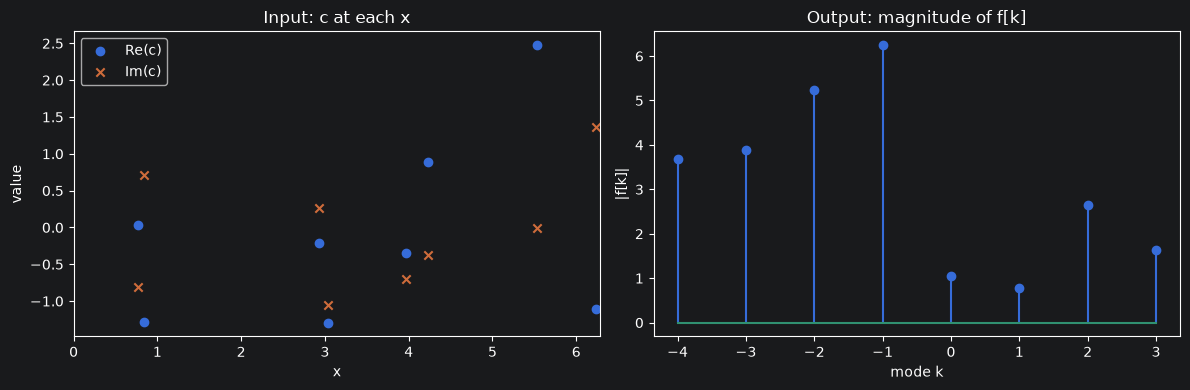

In [10]:
import matplotlib.pyplot as plt

k = np.arange(-N//2, N//2)   # mode labels for f

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.scatter(x, c.real, label="Re(c)")
ax1.scatter(x, c.imag, label="Im(c)", marker="x")
ax1.set_xlim(0, 2 * np.pi)
ax1.set_xlabel("x")
ax1.set_ylabel("value")
ax1.set_title("Input: c at each x")
ax1.legend()

ax2.stem(k, np.abs(f))
ax2.set_xlabel("mode k")
ax2.set_ylabel("|f[k]|")
ax2.set_title("Output: magnitude of f[k]")

plt.tight_layout()
plt.show()

In [11]:
k = np.arange(-N//2, N//2)
f_direct = (c * np.exp(1j * np.outer(k, x))).sum(axis=1)   # O(NM) reference

for eps in [1e-2, 1e-4, 1e-6, 1e-8, 1e-10, 1e-12]:
    f_eps = finufft.nufft1d1(x, c, N, eps=eps)
    print(eps, np.linalg.norm(f_eps - f_direct) / np.linalg.norm(f_direct))

0.01 0.015950097190712876
0.0001 9.545716551307814e-06
1e-06 2.9300356812648854e-08
1e-08 1.0169038193947626e-10
1e-10 1.9045270484465996e-11
1e-12 3.2978331969028083e-13


In [24]:
import time
import numpy as np
import finufft
import matplotlib.pyplot as plt

def median_time(fn, reps=5):
    fn()
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter()
        fn()
        ts.append(time.perf_counter() - t0)
    return np.median(ts)

In [25]:
# problem sizes: number of nonuniform points M = number of modes N = 2^p
sizes = [2**p for p in range(6, 13)]
t_direct, t_nufft, rel_err = [], [], []

for n in sizes:
    # the nonuniform points
    x = 2 * np.pi * np.random.uniform(size=n)

    # their complex strengths
    c = (np.random.standard_normal(size=n)
        + 1J * np.random.standard_normal(size=n))

    # the uniform output mode labels
    k = np.arange(-n//2, n//2)

    # O(NM) direct sum (reference) vs the NUFFT
    direct = lambda: (c * np.exp(1J * np.outer(k, x))).sum(axis=1)
    fast = lambda: finufft.nufft1d1(x, c, n)

    t_direct.append(median_time(direct))
    t_nufft.append(median_time(fast))
    rel_err.append(np.linalg.norm(fast() - direct()) / np.linalg.norm(direct()))

# the NUFFT should be about the direct sum, to around the default tolerance 1e-6
assert max(rel_err) < 10 * 1e-6, rel_err

for name, t in [("direct", t_direct), ("nufft ", t_nufft)]:
    slope = np.polyfit(np.log(sizes[-4:]), np.log(t[-4:]), 1)[0]
    print(f"{name} slope ~ {slope:.2f}")

direct slope ~ 2.00
nufft  slope ~ 0.07


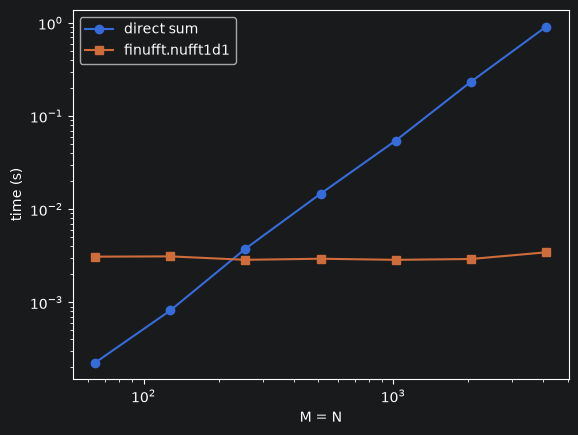

In [26]:
plt.loglog(sizes, t_direct, "o-", label="direct sum")
plt.loglog(sizes, t_nufft, "s-", label="finufft.nufft1d1")
plt.xlabel("M = N")
plt.ylabel("time (s)")
plt.legend()
plt.show()

## now we try to break it

In [15]:
N = M = 8
k = np.arange(-N//2, N//2)
width = 0.1 # what if all the data points are clustered, extremely close to one another

In [16]:
x = np.pi + width * (np.random.uniform(size=M) - 0.5) # M points in a tiny interval around pi
print(x.min(), x.max())
print(np.min(np.diff(np.sort(x))), 2*np.pi/N) # we compare whatever smallest gap between points that exist, with a relatively small gap 2pi/N

3.0917173975274577 3.164705274605487
0.002616556283722371 0.7853981633974483


In [17]:
A = np.exp(1J * np.outer(k, x)) # build that transform as a matrix to be our reference against FINUFFT
U, S, Vh = np.linalg.svd(A) # singular values S, needed for the worst-case input later
print(S[0] / S[-1]) # condition number

2323268602921836.5


In [18]:
c = np.random.standard_normal(M) + 1J * np.random.standard_normal(M) # random strengths
f_exact = A @ c # exact answer from the matrix
f_fast = finufft.nufft1d1(x, c, N) # the NUFFT
print(np.linalg.norm(f_fast - f_exact) / np.linalg.norm(f_exact))

1.9407155257957104e-08


In [19]:
c_bad = np.ascontiguousarray(Vh[-1].conj())# input along the smallest singular direction
f_exact = A @ c_bad
f_fast = finufft.nufft1d1(x, c_bad, N)
print(np.linalg.norm(f_fast - f_exact) / np.linalg.norm(f_exact))

245798.7762016688


But this is just catastrophic cancellation.

In [23]:
# accuracy?
errs = []
for _ in range(100):
    x = np.pi + width * (np.random.uniform(size=M) - 0.5)
    A = np.exp(1J * np.outer(k, x))
    c = np.random.standard_normal(M) + 1J * np.random.standard_normal(M)
    f_exact = A @ c
    f_fast = finufft.nufft1d1(x, c, N)
    errs.append(np.linalg.norm(f_fast - f_exact) / np.linalg.norm(f_exact))
print(np.median(errs), np.max(errs))

2.764162313011867e-08 1.005780081805202e-07


It looks good!